In [2]:
import pandas as pd

cloud_df = pd.read_csv("/workspaces/TDA-workspace/data/Point clouds-selected/control t=0 centroids name=stewie.csv")

In [3]:
cloud_df.head()

,object_id,timestep,Size in pixels,Center of the object_0,Center of the object_1,Center of the object_2
0,0,0,3939,193.67,59.08,6.19
1,1,0,3318,236.24,86.05,4.14
2,2,0,9619,150.10,108.53,5.62
3,3,0,453,208.31,106.72,1.62
4,4,0,3195,257.26,114.08,3.02


<Axes: title={'center': 'Persistence diagram'}, xlabel='Birth', ylabel='Death'>

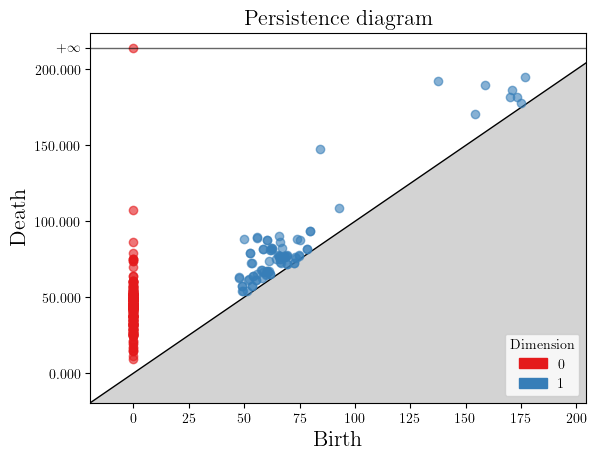

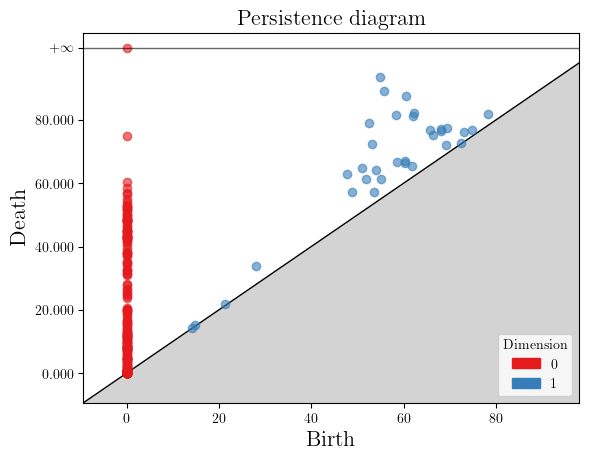

In [26]:
import gudhi as gd
import numpy as np

pts = cloud_df[["Center of the object_0", "Center of the object_1", "Center of the object_2"]].values
pts2 = cloud_df[["Center of the object_0", "Center of the object_1", "Center of the object_2"]].values

rips = gd.RipsComplex(points=pts)
simplex_tree = rips.create_simplex_tree(max_dimension=2)
simplex_tree.compute_persistence()
diag = simplex_tree.persistence()

gd.plot_persistence_diagram(diag)

rips2 = gd.RipsComplex(points=pts2)
simplex_tree2 = rips2.create_simplex_tree(max_dimension=2)
simplex_tree2.compute_persistence()
diag2 = simplex_tree2.persistence() 
gd.plot_persistence_diagram(diag2)



In [27]:
# Sort by dimension, then birth, then death
diag_sorted = sorted(diag)
diag2_sorted = sorted(diag2)

print(f"Sorted diagrams match: {diag_sorted == diag2_sorted}")


Sorted diagrams match: False


In [28]:
# Check if they have the same number of features
print(len(diag), len(diag2))

# Calculate distance (should be near 0)
dist = gd.bottleneck_distance(diag, diag2)
print(f"Bottleneck distance: {dist}")


340 281


ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 2 dimensions. The detected shape was (340, 2) + inhomogeneous part.

In [29]:
# 1. Compare the number of simplices in the trees
print(f"Tree 1 simplices: {simplex_tree.num_simplices()}")
print(f"Tree 2 simplices: {simplex_tree2.num_simplices()}")

# 2. Check the number of points per dimension
from collections import Counter
print("Dim counts 1:", Counter([p[0] for p in diag]))
print("Dim counts 2:", Counter([p[0] for p in diag2]))

# 3. Check for 'zero-length' bars that might be getting filtered
# Bars where birth == death are sometimes omitted
diag_no_zeros = [p for p in diag if p[1][0] != p[1][1]]
diag2_no_zeros = [p for p in diag2 if p[1][0] != p[1][1]]
print(f"Non-zero bars: {len(diag_no_zeros)} vs {len(diag2_no_zeros)}")


Tree 1 simplices: 2667378
Tree 2 simplices: 2667378
Dim counts 1: Counter({0: 252, 1: 88})
Dim counts 2: Counter({0: 248, 1: 33})
Non-zero bars: 340 vs 281


<Axes: title={'center': 'Persistence diagram'}, xlabel='Birth', ylabel='Death'>

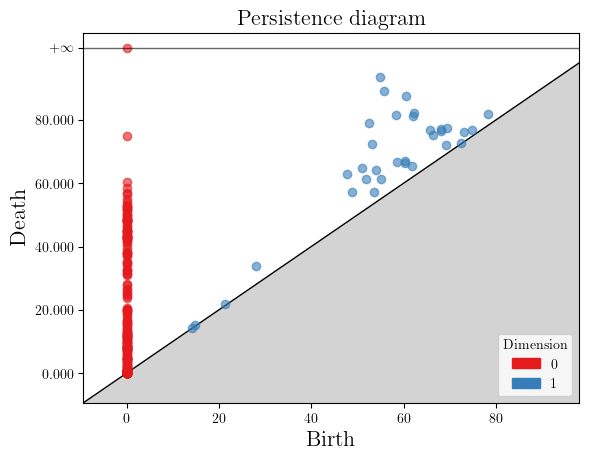

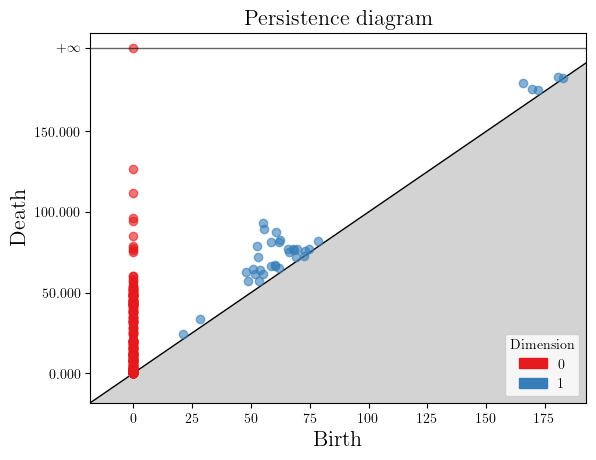

In [30]:
pts = np.round(pts, decimals=10)
pts2 = np.round(pts2, decimals=10)

rips = gd.RipsComplex(points=pts)
simplex_tree = rips.create_simplex_tree(max_dimension=2)
simplex_tree.compute_persistence()
diag = simplex_tree.persistence()

gd.plot_persistence_diagram(diag)

rips2 = gd.RipsComplex(points=pts2)
simplex_tree2 = rips2.create_simplex_tree(max_dimension=2)
simplex_tree2.compute_persistence()
diag2 = simplex_tree2.persistence() 
gd.plot_persistence_diagram(diag2)



In [31]:
# 1. Compare the number of simplices in the trees
print(f"Tree 1 simplices: {simplex_tree.num_simplices()}")
print(f"Tree 2 simplices: {simplex_tree2.num_simplices()}")

# 2. Check the number of points per dimension
from collections import Counter
print("Dim counts 1:", Counter([p[0] for p in diag]))
print("Dim counts 2:", Counter([p[0] for p in diag2]))

# 3. Check for 'zero-length' bars that might be getting filtered
# Bars where birth == death are sometimes omitted
diag_no_zeros = [p for p in diag if p[1][0] != p[1][1]]
diag2_no_zeros = [p for p in diag2 if p[1][0] != p[1][1]]
print(f"Non-zero bars: {len(diag_no_zeros)} vs {len(diag2_no_zeros)}")


Tree 1 simplices: 2667378
Tree 2 simplices: 2667378
Dim counts 1: Counter({0: 248, 1: 33})
Dim counts 2: Counter({0: 250, 1: 36})
Non-zero bars: 281 vs 286


In [32]:
# Check if they have the same number of features
print(len(diag), len(diag2))

# Calculate distance (should be near 0)
dist = gd.bottleneck_distance(diag, diag2)
print(f"Bottleneck distance: {dist}")

281 286


ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 2 dimensions. The detected shape was (281, 2) + inhomogeneous part.

In [33]:
print(f"NaNs in pts: {np.isnan(pts).any()}")
print(f"NaNs in pts2: {np.isnan(pts2).any()}")


NaNs in pts: False
NaNs in pts2: False


In [34]:
import copy

pts = cloud_df[["Center of the object_0", "Center of the object_1", "Center of the object_2"]].values.copy()
pts2 = copy.deepcopy(pts) # Force a completely independent copy

rips1 = gd.RipsComplex(points=pts)
st1 = rips1.create_simplex_tree(max_dimension=2)
print(f"Tree 1: {st1.num_simplices()}")

rips2 = gd.RipsComplex(points=pts2)
st2 = rips2.create_simplex_tree(max_dimension=2)
print(f"Tree 2: {st2.num_simplices()}")


Tree 1: 98854
Tree 2: 98854


In [35]:
st1.compute_persistence()
diag1 = st1.persistence()

st2.compute_persistence()
diag2 = st2.persistence()

print(f"Final Count 1: {len(diag1)}")
print(f"Final Count 2: {len(diag2)}")
print(f"Exactly equal: {diag1 == diag2}")


Final Count 1: 114
Final Count 2: 114
Exactly equal: True


In [ ]:
diag = st1.persistence()
diag2 = st2.persistence()   

gd.plot_persistence_diagram(diag)
gd.plot_persistence_diagram(diag2)